# Estrategia USD/CLP · modelo adaptativo de 11 variables

In [1]:
import sys, warnings; warnings.filterwarnings('ignore'); sys.path.insert(0, 'codigo')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import modelo_adaptativo as M

XLSX, MODO, W, T_MIN, COSTO_BPS = 'datos/base_usdclp.xlsx', 'torneo', M.W_FIJO, M.TMIN_FIJO, 3.0
PERIODOS = {'2023': ('2023', '2023'), '2024-2025': ('2024', '2025'), '2026 (hasta 6 oct)': ('2026-01-01', '2026-10-05'),
            'Datos nuevos (7 oct-6 nov)': ('2026-10-06', '2026-11-05')}   # fechas de decisión; resultado al cierre siguiente

## 1. Modelos y supuestos

**Datos y ventana**
- Calendario: jornadas del USD/CLP desde 2004. Se excluyen los días con máximo igual al mínimo, que son cotizaciones rancias de feriados chilenos. La muestra de modelado parte en 2005.
- Datos faltantes: se usa el último valor disponible, con un máximo de 5 días. Cada señal se divide por su desviación estándar móvil de 250 jornadas y se recorta a ±5.
- `FECHA_RELEASE`: no se usan series macro con fecha de publicación, así que no hay sesgo por rezago de publicación. Las tasas en dólares (Fed Funds y SOFR) entran con 1 día de rezago.
- Regla de información (modo `torneo`): todos los cierres de una misma fecha se consideran disponibles al decidir, según la regla del diccionario de la base.
- Período de análisis: los resultados se reportan desde 2023, el régimen actual del peso. Desde 2023–2024 su retorno propio pasó de la tendencia a la reversión, y su movimiento frente a los pares y el swap a 5 años ganaron peso. La historia desde 2005 se usa solo para calcular las ventanas móviles. Antes de 2023 este conjunto de variables no mostraba un poder predictivo consistente: entre 2016 y 2022 su acierto fue cercano al 50% y su resultado neto, negativo.

**Señales (11):**
- Dólar global: `bbdxy_r1`.
- Bolsas: emergentes `mxef_r1` y Shanghai `shcomp_r1`.
- Commodities: oro `gold_r1` y cobre a 1 y 5 días (`hg_r1`, `hg_r5`).
- Tasas: base NDF 1M menos cámara `ndf_basis_z` y swap a 5 años `cl5y_d1`.
- Propias del peso: retorno a 1 y 5 días (`clp_r1`, `clp_r5`) y movimiento propio frente al BRL, el MXN y el ZAR (`res_em_1`).

**Modelo**
1. *Pesos dinámicos*: el peso de cada señal es su correlación con el retorno del día siguiente en las últimas W = 250 jornadas, usando solo retornos ya conocidos. Si |IC|·√W ≤ 1, el peso es 0.
2. *Score* = Σ peso × señal. La dirección es el signo del score.
3. *Probabilidad*: regresión logística móvil del score (ventana de 500 jornadas, reajuste cada 21), usando solo el pasado.
4. *Exposición*: ±1 cuando |score| supera la mediana móvil de 250 jornadas, rezagada 1 día; 0 en los demás días. No se usa ±3.

**Selección**
- Las 11 señales salieron de 16 candidatas por eliminación hacia atrás, maximizando el acierto de 2024–2025.
- W y el umbral se fijaron en 250 y 1 con una grilla sobre 2016–2025.
- 2026 se observó durante el desarrollo (al comparar versiones del modelo), así que no es un tramo de prueba estrictamente limpio.

**Datos nuevos**
- La base llega al 6 de noviembre de 2026.
- Las 22 jornadas posteriores al 6 de octubre se incorporaron después del desarrollo y se evalúan como prueba hacia adelante, sin modificar variables, parámetros ni reglas.
- Hasta el 6 de octubre, los resultados son idénticos a los de la base anterior.

In [2]:
Z, F = M.señales(M.cargar(XLSX), MODO)
score, pesos = M.score_dinamico(Z, F, W, T_MIN)
prob = M.probabilidad(score, F)
pos = M.exposicion(score)

## 2. Mecanismo de ejecución

- **Momento de la señal:** al cierre de la jornada *t*, con todos los cierres de *t* disponibles.
- **Precio de ejecución:** cierre del USD/CLP (`USDCLP Curncy|PX_LAST`) de *t*. La posición se mantiene del cierre *t* al cierre *t+1*. No se usa la apertura (`PX_OPEN`) ni el dólar observado (`CLFXDOOB`).
- **Reglas de operación:**
  - **Compra USD (+1):** score > 0 y |score| ≥ mediana móvil de |score| (250 jornadas, calculada hasta *t−1*).
  - **Venta USD (−1):** score < 0 y |score| ≥ esa mediana.
  - **Cierre o abstención (0):** |score| < esa mediana.
  - Un cambio de signo pasa directo de +1 a −1, o al revés.
- **Feriados chilenos** (días excluidos del calendario): la posición vigente se mantiene hasta la siguiente jornada.
- **Resultado diario:** exposición × (retorno cierre a cierre − carry) − costo.
  - **Carry:** tasa cámara (índice `CLICP`) menos Fed Funds/SOFR, prorrateada por días corridos / 360. La paga el largo en USD.
  - **Costo:** 3 pb por unidad de exposición transada, |pos_t − pos_{t−1}|.

In [3]:
ult = score.dropna().index[-1]
pd.Series({'fecha_cierre': ult.date(), 'direccion': 'SUBE' if score[ult] > 0 else 'BAJA',
           'prob_sube': round(float(prob[ult]), 4), 'exposicion': float(pos[ult])}, name='señal del día')

fecha_cierre    2026-11-06
direccion             BAJA
prob_sube           0.4892
exposicion             0.0
Name: señal del día, dtype: object

## 3. Resumen de backtesting y estadísticas de trading

In [4]:
def estadisticas(p, a, b):
    p = p[a:b]; p = p[F.ret_fwd.reindex(p.index).notna()]
    _, neto = M.pnl(p, F, COSTO_BPS); eq = (1 + neto).cumprod(); activo = p != 0
    return {'retorno_neto_%': 100 * (eq.iloc[-1] - 1),
            'volatilidad_anual_%': 100 * neto.std() * np.sqrt(252),
            'sharpe': neto.mean() / neto.std() * np.sqrt(252) if neto.std() > 0 else 0.0,
            'max_drawdown_%': 100 * (eq / eq.cummax() - 1).min(),
            'win_rate_%': 100 * (np.sign(p) == np.sign(F.ret_fwd[p.index]))[activo].mean() if activo.any() else np.nan,
            'n_operaciones': int((p.diff().fillna(p) != 0).sum()),
            'dias_operados_%': 100 * activo.mean()}

estrategias = {'Estrategia': pos,
               'Comprar siempre': pd.Series(1.0, index=pos.index),
               'No operar': pd.Series(0.0, index=pos.index),
               'Exposición uno': np.sign(prob - 0.5).fillna(0) + 0.0}
tabla = pd.concat({per: pd.DataFrame({k: estadisticas(v, a, b) for k, v in estrategias.items()}).T
                   for per, (a, b) in PERIODOS.items()})
tabla.round(2)

retorno_neto_%  \
2023                       Estrategia                 1.16   
                           Comprar siempre           -2.59   
                           No operar                  0.00   
                           Exposición uno             1.65   
2024-2025                  Estrategia                 8.89   
                           Comprar siempre            0.61   
                           No operar                  0.00   
                           Exposición uno            15.30   
2026 (hasta 6 oct)         Estrategia                 8.82   
                           Comprar siempre            6.69   
                           No operar                  0.00   
                           Exposición uno             1.74   
Datos nuevos (7 oct-6 nov) Estrategia                 2.34   
                           Comprar siempre            0.39   
                           No operar                  0.00   
                           Exposición uno             5.59   

                                            volatilidad_anual_%  sharpe  \
2023                       Estrategia                     10.87    0.16   
                           Comprar siempre                14.06   -0.12   
                           No operar                       0.00    0.00   
                           Exposición uno                 14.08    0.19   
2024-2025                  Estrategia                      8.54    0.55   
                           Comprar siempre                12.06    0.09   
                           No operar                       0.00    0.00   
                           Exposición uno                 12.02    0.66   
2026 (hasta 6 oct)         Estrategia                     11.43    1.03   
                           Comprar siempre                13.43    0.70   
                           No operar                       0.00    0.00   
                           Exposición uno                 13.43    0.24   
Datos nuevos (7 oct-6 nov) Estrategia                      6.12    4.36   
                           Comprar siempre                11.50    0.44   
                           No operar                       0.00    0.00   
                           Exposición uno                 10.59    5.93   

                                            max_drawdown_%  win_rate_%  \
2023                       Estrategia                -9.39       52.32   
                           Comprar siempre          -10.56       51.19   
                           No operar                  0.00         NaN   
                           Exposición uno           -15.75       51.59   
2024-2025                  Estrategia               -10.48       56.17   
                           Comprar siempre          -12.25       48.29   
                           No operar                  0.00         NaN   
                           Exposición uno           -14.11       55.13   
2026 (hasta 6 oct)         Estrategia                -5.47       55.80   
                           Comprar siempre           -6.07       54.17   
                           No operar                  0.00         NaN   
                           Exposición uno            -6.94       53.12   
Datos nuevos (7 oct-6 nov) Estrategia                -0.98       70.00   
                           Comprar siempre           -3.00       59.09   
                           No operar                  0.00         NaN   
                           Exposición uno            -1.81       63.64   

                                            n_operaciones  dias_operados_%  
2023                       Estrategia               118.0            59.92  
                           Comprar siempre            1.0           100.00  
                           No operar                  0.0             0.00  
                           Exposición uno           100.0           100.00  
2024-2025                  Estrategia               245.0            

In [5]:
# Diebold-Mariano (predicción y resultado) y bootstrap por bloques (p-valores)
cols = ['DM_p', 'DM_resultado_p_vs_comprar_siempre', 'DM_resultado_p_vs_no_operar', 'DM_resultado_p_vs_exposicion_uno',
        'boot_p_vs_comprar_siempre', 'boot_p_vs_no_operar', 'boot_p_vs_exposicion_uno']
# no se calculan para datos nuevos: con 22 jornadas las pruebas no tienen potencia
pd.DataFrame({per: M.metricas(prob, pos[a:b], F, COSTO_BPS) for per, (a, b) in list(PERIODOS.items())[:-1]}).loc[cols].round(3)

,2023,2024-2025,2026 (hasta 6 oct)
DM_p,0.328,0.395,0.793
DM_resultado_p_vs_comprar_siempre,0.866,0.684,0.902
DM_resultado_p_vs_no_operar,0.870,0.456,0.319
DM_resultado_p_vs_exposicion_uno,0.920,0.576,0.180
boot_p_vs_comprar_siempre,0.423,0.315,0.468
boot_p_vs_no_operar,0.428,0.226,0.131
boot_p_vs_exposicion_uno,0.545,0.722,0.072


## 4. Gráficos de la estrategia

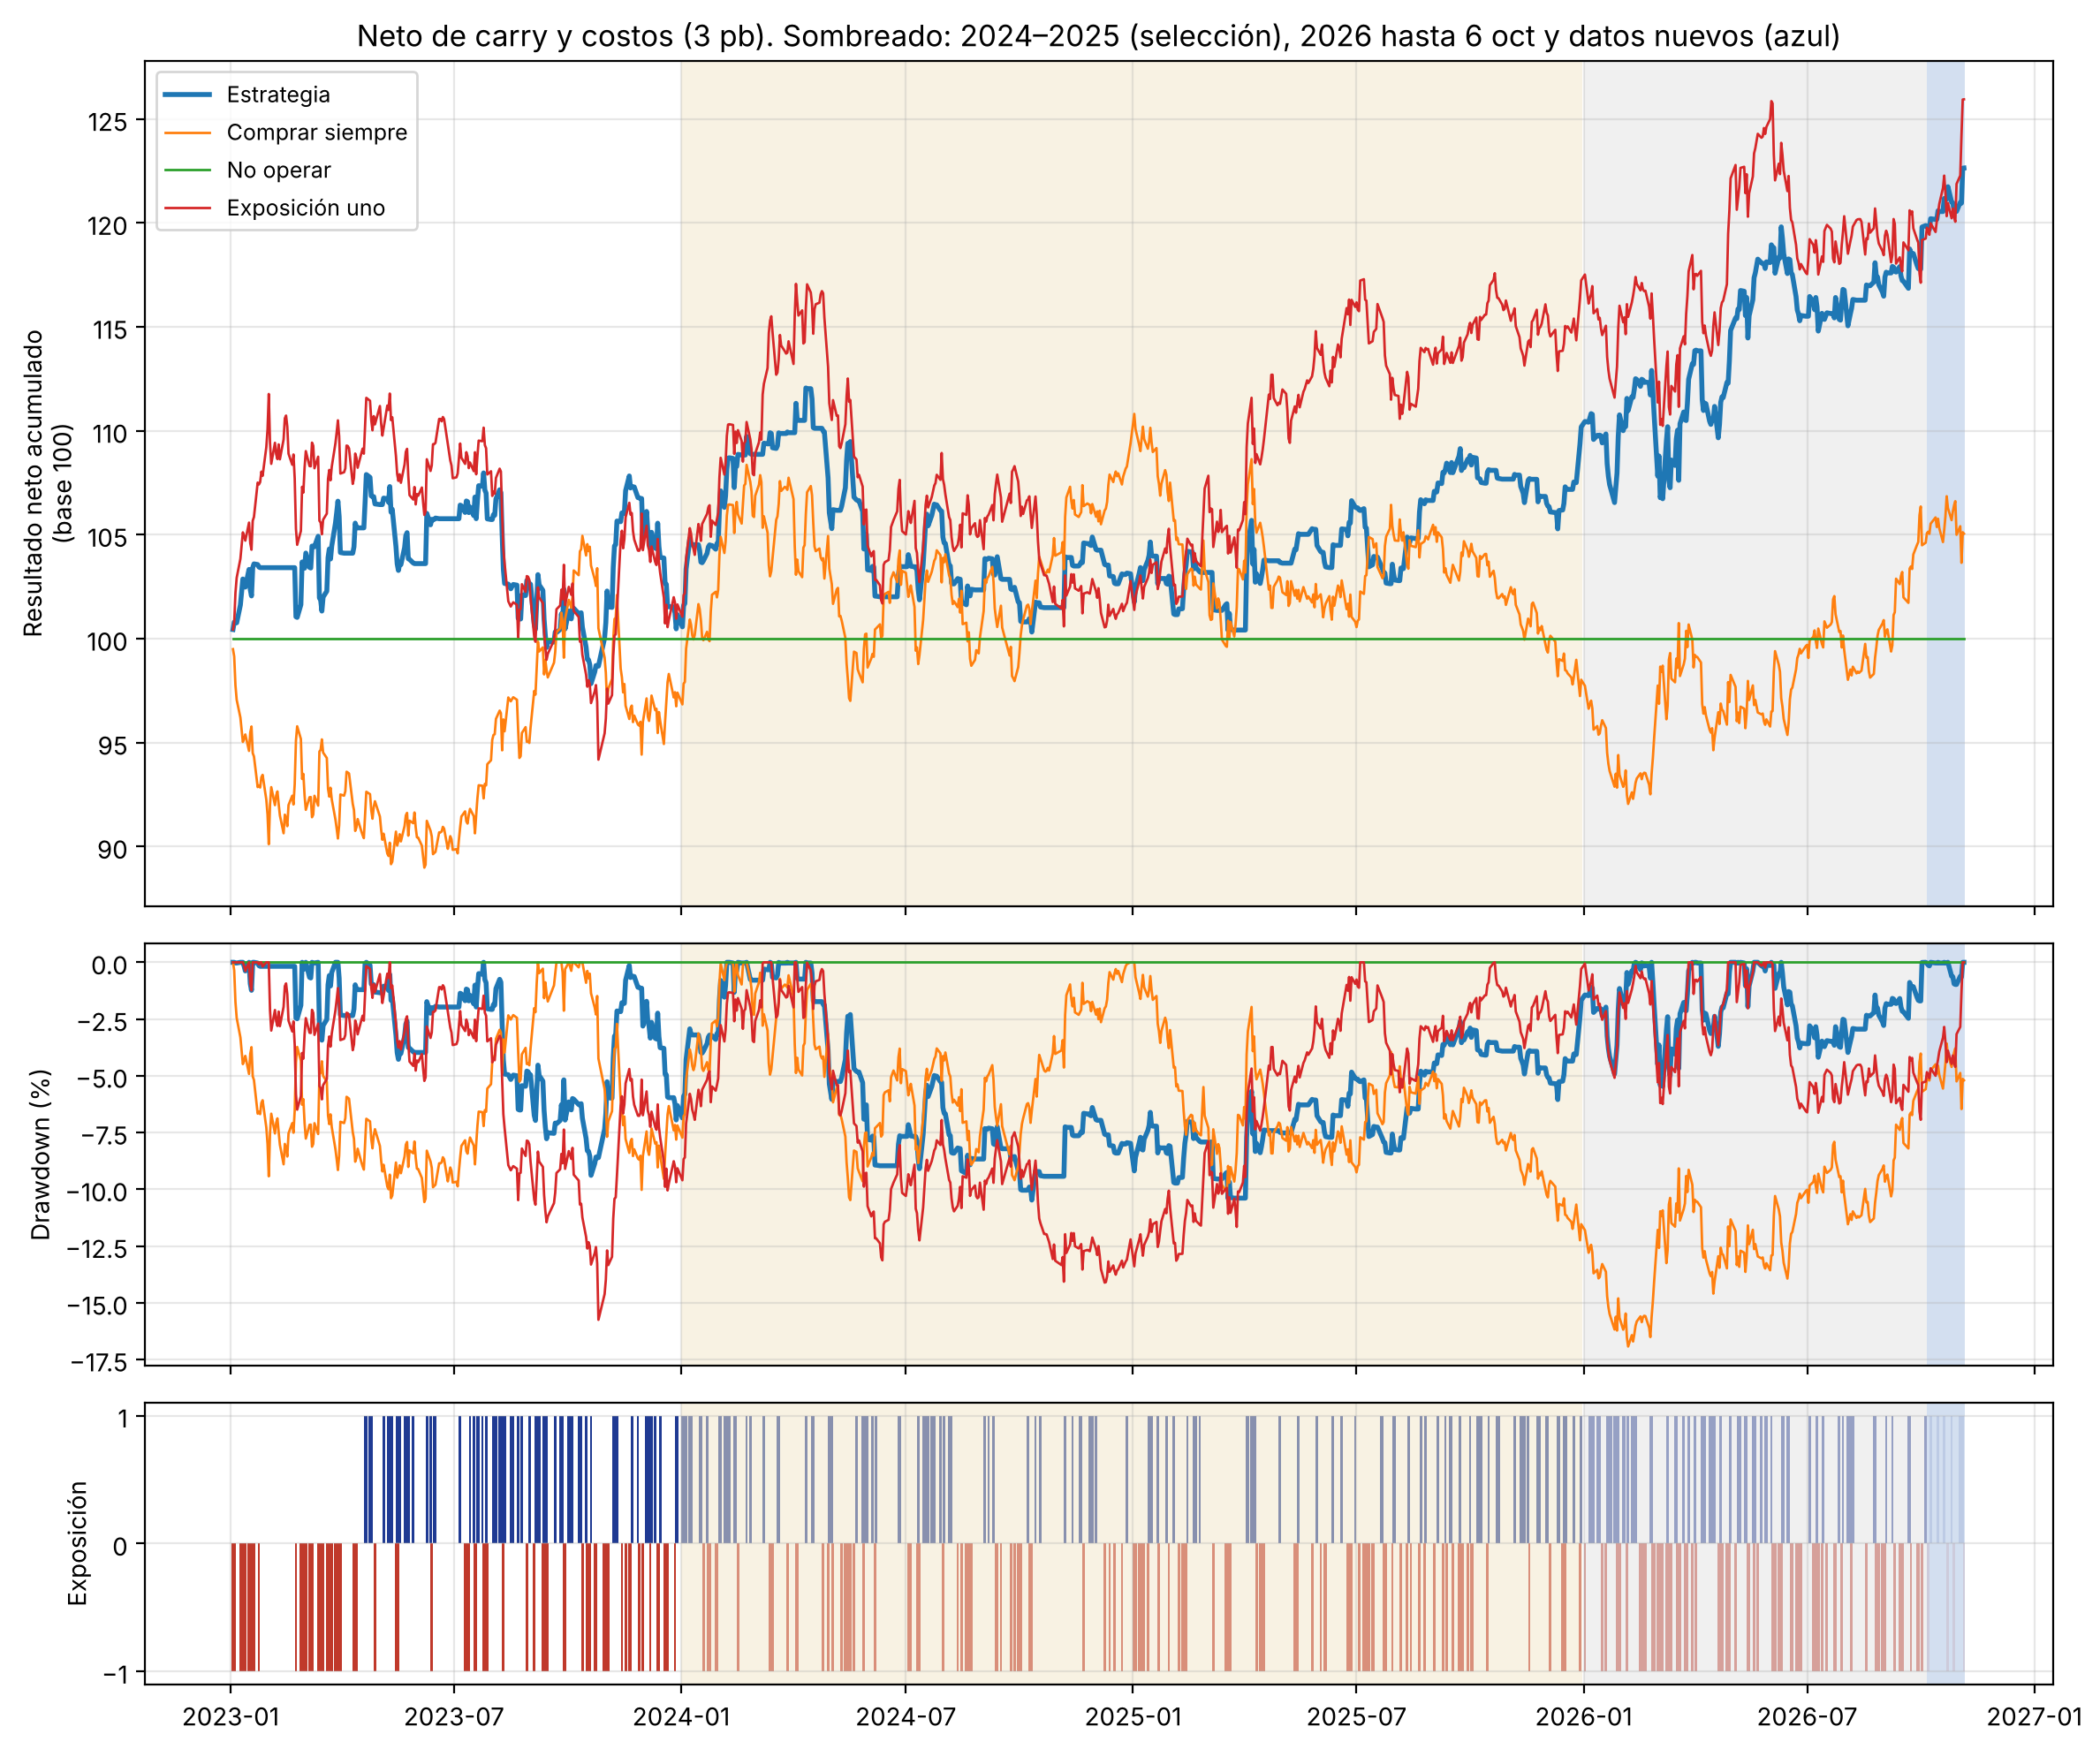

In [6]:
desde = '2023'
fig, ax = plt.subplots(3, 1, figsize=(12, 10), sharex=True, gridspec_kw={'height_ratios': [3, 1.5, 1]})
for k, v in estrategias.items():
    p = v[desde:]; p = p[F.ret_fwd.reindex(p.index).notna()]
    _, neto = M.pnl(p, F, COSTO_BPS); eq = (1 + neto).cumprod()
    lw = 2 if k == 'Estrategia' else 1
    ax[0].plot(100 * eq, lw=lw, label=k)
    ax[1].plot(100 * (eq / eq.cummax() - 1), lw=lw, label=k)
p = pos[desde:]
ax[2].bar(p.index, p.values, width=2, color=np.where(p > 0, '#1f3a93', '#c0392b'))
for a in ax:
    a.axvspan(pd.Timestamp('2024-01-01'), pd.Timestamp('2025-12-31'), color='#f2e6c9', alpha=.5, lw=0)
    a.axvspan(pd.Timestamp('2026-01-01'), pd.Timestamp('2026-10-06'), color='#e6e6e6', alpha=.6, lw=0)
    a.axvspan(pd.Timestamp('2026-10-06'), p.index[-1], color='#cfdcef', alpha=.9, lw=0)
    a.grid(alpha=.3)
ax[0].set_ylabel('Resultado neto acumulado\n(base 100)'); ax[0].legend(loc='upper left', fontsize=9)
ax[0].set_title('Neto de carry y costos (3 pb). Sombreado: 2024–2025 (selección), 2026 hasta 6 oct y datos nuevos (azul)')
ax[1].set_ylabel('Drawdown (%)'); ax[2].set_ylabel('Exposición'); ax[2].set_yticks([-1, 0, 1])
plt.tight_layout(); plt.show()